# Day 4: Colour Images, Data Augmentation and CIFAR-10
**Deep Learning Internship, Phase 2 (CNNs)**

Goals: (1) work with 3-channel colour images (CIFAR-10), (2) train a CNN **without** augmentation and note the overfitting gap, (3) add `RandomHorizontalFlip` and `RandomCrop` (training set only) and compare, (4) optionally add a learning-rate scheduler.

> Use Colab with a **T4 GPU**. On a CPU, set `EPOCHS = 3` first, because CIFAR-10 is slower than Fashion-MNIST.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


## 1. CIFAR-10 data
60,000 colour images of size 3x32x32 in 10 classes (50,000 train, 10,000 test). It is harder than Fashion-MNIST: colour, varied backgrounds, and small objects.
**Augmentation is applied to the training set only.** Validation and test images stay untouched, so the scores reflect real data.

In [2]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

plain_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(CIFAR_MEAN, CIFAR_STD)])
aug_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

train_plain = datasets.CIFAR10("./data", train=True, download=True, transform=plain_tf)
train_aug = datasets.CIFAR10("./data", train=True, download=True, transform=aug_tf)
test_set = datasets.CIFAR10("./data", train=False, download=True, transform=plain_tf)
classes = train_plain.classes

# Same 45,000 / 5,000 split for both versions
perm = torch.randperm(50000, generator=torch.Generator().manual_seed(42)).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]

val_set = Subset(train_plain, val_idx)             # validation: never augmented
train_set_plain = Subset(train_plain, train_idx)   # training without augmentation
train_set_aug = Subset(train_aug, train_idx)       # augmentation ONLY on training images

BATCH_SIZE = 128
train_loader_plain = DataLoader(train_set_plain, batch_size=BATCH_SIZE, shuffle=True)
train_loader_aug = DataLoader(train_set_aug, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE)

print("train / val / test:", len(train_set_plain), len(val_set), len(test_set))
print(classes)

100%|██████████| 170M/170M [00:14<00:00, 12.1MB/s]


train / val / test: 45000 5000 10000
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


one batch: torch.Size([128, 3, 32, 32]) (batch, channels, height, width)


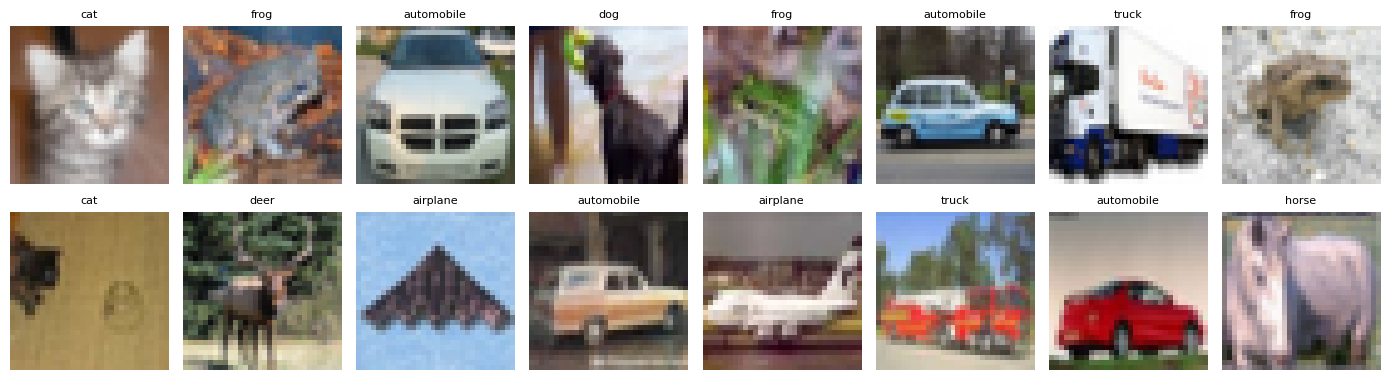

In [3]:
def unnormalize(img):
    mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR_STD).view(3, 1, 1)
    return (img.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0)

images, labels = next(iter(train_loader_plain))
print("one batch:", images.shape, "(batch, channels, height, width)")

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lab in zip(axes.ravel(), images, labels):
    ax.imshow(unnormalize(img))
    ax.set_title(classes[lab], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. What augmentation does
One training image, shown with several random flips and crops.

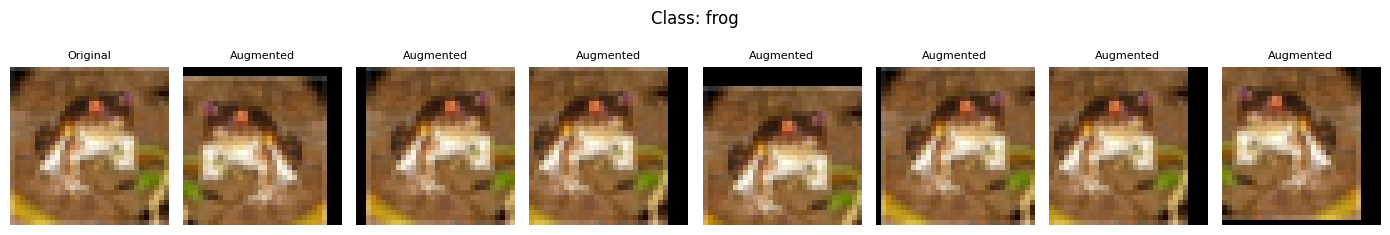

In [4]:
raw = datasets.CIFAR10("./data", train=True, download=True)       # PIL images, no transform
aug_only = transforms.Compose([transforms.RandomHorizontalFlip(), transforms.RandomCrop(32, padding=4)])

pil_img, lab = raw[0]
fig, axes = plt.subplots(1, 8, figsize=(14, 2.5))
axes[0].imshow(pil_img); axes[0].set_title("Original", fontsize=8)
for ax in axes[1:]:
    ax.imshow(aug_only(pil_img)); ax.set_title("Augmented", fontsize=8)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"Class: {classes[lab]}")
plt.tight_layout()
plt.show()

## 3. CNN for colour images
Same idea as Day 3, but the first conv layer takes **3 input channels**.
Shape: `3x32x32 -> 32x16x16 -> 64x8x8 -> 128x4x4 -> 2048 -> 256 -> 10`

In [5]:
class CIFARNet(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()

        def block(i, o):
            return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2)]

        self.features = nn.Sequential(*block(3, 32), *block(32, 64), *block(64, 128))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


m = CIFARNet().to(device).eval()
x = torch.randn(1, 3, 32, 32).to(device)
with torch.no_grad():
    for layer in list(m.features) + list(m.classifier):
        x = layer(x)
        print(f"{layer.__class__.__name__:<12} -> {tuple(x.shape)}")
print("Parameters:", f"{sum(p.numel() for p in m.parameters()):,}")

Conv2d       -> (1, 32, 32, 32)
BatchNorm2d  -> (1, 32, 32, 32)
ReLU         -> (1, 32, 32, 32)
MaxPool2d    -> (1, 32, 16, 16)
Conv2d       -> (1, 64, 16, 16)
BatchNorm2d  -> (1, 64, 16, 16)
ReLU         -> (1, 64, 16, 16)
MaxPool2d    -> (1, 64, 8, 8)
Conv2d       -> (1, 128, 8, 8)
BatchNorm2d  -> (1, 128, 8, 8)
ReLU         -> (1, 128, 8, 8)
MaxPool2d    -> (1, 128, 4, 4)
Flatten      -> (1, 2048)
Linear       -> (1, 256)
ReLU         -> (1, 256)
Dropout      -> (1, 256)
Linear       -> (1, 10)
Parameters: 620,810


## 4. Training helpers

In [6]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total


def fit(model, train_loader, epochs, lr=1e-3, use_scheduler=False):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs) if use_scheduler else None
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val, best_state = 0.0, None
    start = time.time()
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        if scheduler:
            scheduler.step()
        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
        if va_acc > best_val:
            best_val = va_acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"Epoch {epoch:2d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} "
              f"| val loss {va_loss:.4f} acc {va_acc:.4f}")
    history["time"] = time.time() - start
    return history, best_state

## 5. Experiments
Every experiment starts from the same seed and the same model, so the **only** difference is the training data pipeline.

In [7]:
EPOCHS = 15       # use 3 on a CPU first
criterion = nn.CrossEntropyLoss()
results = {}


def experiment(name, train_loader, use_scheduler=False):
    print(f"\n=== {name} ===")
    torch.manual_seed(42)
    model = CIFARNet().to(device)
    hist, state = fit(model, train_loader, EPOCHS, use_scheduler=use_scheduler)
    model.load_state_dict(state)
    _, test_acc = run_epoch(model, test_loader, criterion)
    results[name] = {"hist": hist, "test_acc": test_acc, "params": count_params(model)}
    print(f"Test accuracy: {test_acc:.4f}")


experiment("No augmentation", train_loader_plain)
experiment("With augmentation", train_loader_aug)


=== No augmentation ===
Epoch  1/15 | train loss 1.3013 acc 0.5270 | val loss 0.9777 acc 0.6578
Epoch  2/15 | train loss 0.9218 acc 0.6754 | val loss 0.8509 acc 0.6990
Epoch  3/15 | train loss 0.7887 acc 0.7253 | val loss 0.7547 acc 0.7332
Epoch  4/15 | train loss 0.7087 acc 0.7543 | val loss 0.7390 acc 0.7410
Epoch  5/15 | train loss 0.6331 acc 0.7789 | val loss 0.7517 acc 0.7340
Epoch  6/15 | train loss 0.5744 acc 0.7971 | val loss 0.6824 acc 0.7636
Epoch  7/15 | train loss 0.5223 acc 0.8172 | val loss 0.6573 acc 0.7746
Epoch  8/15 | train loss 0.4799 acc 0.8290 | val loss 0.7492 acc 0.7528
Epoch  9/15 | train loss 0.4288 acc 0.8471 | val loss 0.6521 acc 0.7774
Epoch 10/15 | train loss 0.3867 acc 0.8621 | val loss 0.6570 acc 0.7816
Epoch 11/15 | train loss 0.3466 acc 0.8767 | val loss 0.6499 acc 0.7984
Epoch 12/15 | train loss 0.3185 acc 0.8845 | val loss 0.6514 acc 0.7952
Epoch 13/15 | train loss 0.2844 acc 0.8967 | val loss 0.6383 acc 0.7994
Epoch 14/15 | train loss 0.2503 acc 0.9

## 6. Optional: learning-rate scheduler
Cosine annealing slowly lowers the learning rate during training, which often gives a small extra gain.

In [8]:
experiment("Augmentation + scheduler", train_loader_aug, use_scheduler=True)


=== Augmentation + scheduler ===
Epoch  1/15 | train loss 1.4821 acc 0.4542 | val loss 1.1299 acc 0.5906
Epoch  2/15 | train loss 1.1481 acc 0.5900 | val loss 0.9857 acc 0.6400
Epoch  3/15 | train loss 1.0237 acc 0.6360 | val loss 0.8799 acc 0.6894
Epoch  4/15 | train loss 0.9428 acc 0.6682 | val loss 0.8059 acc 0.7124
Epoch  5/15 | train loss 0.8847 acc 0.6891 | val loss 0.7595 acc 0.7280
Epoch  6/15 | train loss 0.8326 acc 0.7077 | val loss 0.7340 acc 0.7412
Epoch  7/15 | train loss 0.7924 acc 0.7218 | val loss 0.7113 acc 0.7524
Epoch  8/15 | train loss 0.7527 acc 0.7367 | val loss 0.6425 acc 0.7694
Epoch  9/15 | train loss 0.7191 acc 0.7480 | val loss 0.6386 acc 0.7724
Epoch 10/15 | train loss 0.6889 acc 0.7604 | val loss 0.6404 acc 0.7754
Epoch 11/15 | train loss 0.6601 acc 0.7694 | val loss 0.5953 acc 0.7868
Epoch 12/15 | train loss 0.6414 acc 0.7759 | val loss 0.5833 acc 0.7910
Epoch 13/15 | train loss 0.6219 acc 0.7832 | val loss 0.5745 acc 0.7942
Epoch 14/15 | train loss 0.615

## 7. Compare the curves and the overfitting gap

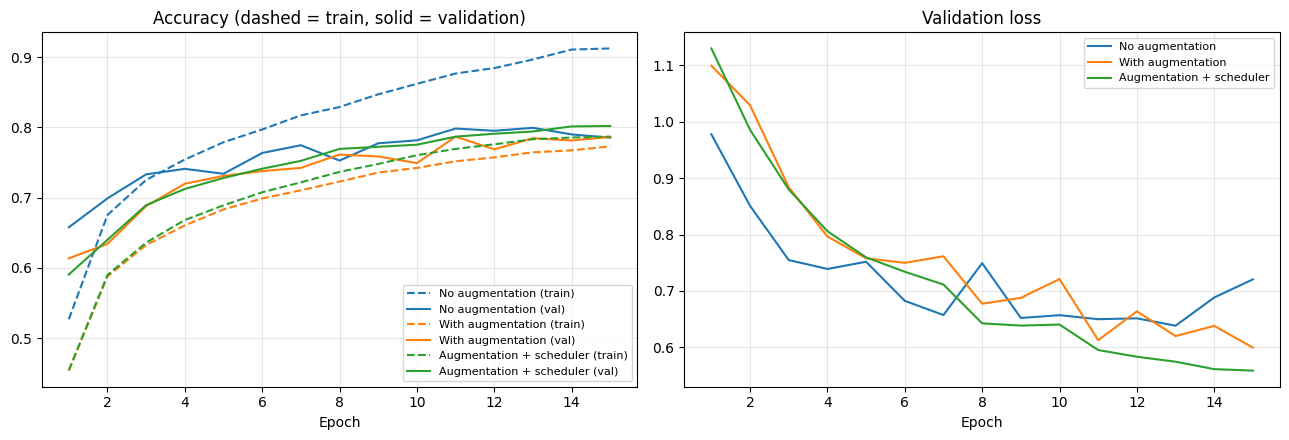

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ep = range(1, EPOCHS + 1)
for name, r in results.items():
    line, = axes[0].plot(ep, r["hist"]["train_acc"], "--", label=f"{name} (train)")
    axes[0].plot(ep, r["hist"]["val_acc"], color=line.get_color(), label=f"{name} (val)")
    axes[1].plot(ep, r["hist"]["val_loss"], label=name)
axes[0].set_title("Accuracy (dashed = train, solid = validation)")
axes[1].set_title("Validation loss")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
print(f"{'Experiment':<26} {'Params':>9} {'Train acc':>10} {'Val acc':>8} {'Gap':>7} {'Test acc':>9} {'Time (s)':>9}")
for name, r in results.items():
    h = r["hist"]
    tr, va = h["train_acc"][-1], h["val_acc"][-1]
    print(f"{name:<26} {r['params']:>9,} {tr:>10.4f} {va:>8.4f} {tr - va:>7.4f} {r['test_acc']:>9.4f} {h['time']:>9.1f}")

Experiment                    Params  Train acc  Val acc     Gap  Test acc  Time (s)
No augmentation              620,810     0.9124   0.7854  0.1270    0.7920     216.9
With augmentation            620,810     0.7730   0.7864 -0.0134    0.7823     310.7
Augmentation + scheduler     620,810     0.7869   0.8020 -0.0151    0.8041     312.7


## Summary (rewrite in your own words)
- Colour images have 3 channels, so the first conv layer uses `in_channels=3`; CIFAR-10 is harder than Fashion-MNIST.
- Without augmentation the training accuracy keeps rising while the validation accuracy stalls, which is **overfitting**: look at the gap column.
- Random flips and crops create new variants of each training image every epoch, so the model cannot just memorise them. Augmentation is used on the training set only.
- Training accuracy with augmentation is usually lower (the task is harder), but validation and test accuracy are usually higher.
- A learning-rate scheduler lowers the learning rate gradually and can add a small gain.
- Next (Day 5): famous architectures (LeNet, VGG, ResNet) and residual connections.